In [20]:
import pandas as pd
import seaborn as srn
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestRegressor
from sklearn.linear_model import LinearRegression
from sklearn import metrics
import joblib

In [21]:
dataset = pd.read_csv(r"C:\Users\henrique_schorck\Documents\GitHub\Projeto-Integrador\Machine_Learning\Dados_CSV\dados_sensores_metaltech.csv")
dataset.head()

,timestamp,id_maquina,temperatura_c,vibracao_mm_s,pressao_bar,falha_motor
0,2026-01-01 00:00:00,M03,67.015129,1.523088,40.672538,0
1,2026-01-01 00:01:00,M04,58.048478,2.738448,38.644490,0
2,2026-01-01 00:02:00,M01,67.938896,2.566715,46.814723,0
3,2026-01-01 00:03:00,M03,74.567369,3.174506,35.055251,0
4,2026-01-01 00:04:00,M03,72.688150,4.642862,42.926834,0


In [22]:
dataset.shape

(10000, 6)

In [23]:
dataset.head()

,timestamp,id_maquina,temperatura_c,vibracao_mm_s,pressao_bar,falha_motor
0,2026-01-01 00:00:00,M03,67.015129,1.523088,40.672538,0
1,2026-01-01 00:01:00,M04,58.048478,2.738448,38.644490,0
2,2026-01-01 00:02:00,M01,67.938896,2.566715,46.814723,0
3,2026-01-01 00:03:00,M03,74.567369,3.174506,35.055251,0
4,2026-01-01 00:04:00,M03,72.688150,4.642862,42.926834,0


In [24]:
dataset.columns = ["Timestamp", "Id_Maquina", "Temperatura_C", "Vibracao_mms", "Pressao_bar", "Falha_motor"]

In [25]:
dataset[["Timestamp", "Id_Maquina", "Temperatura_C", "Vibracao_mms", "Pressao_bar", "Falha_motor"]].describe()

,Temperatura_C,Vibracao_mms,Pressao_bar,Falha_motor
count,9704.000000,9701.000000,9700.000000,10000.000000
mean,81.217879,2.917828,41.689877,0.050000
std,94.196943,5.825520,8.231972,0.217956
min,50.387999,-50.000000,26.603188,0.000000
25%,66.845771,2.666760,38.020922,0.000000
50%,70.343967,3.025045,40.200918,0.000000
75%,74.101811,3.408941,42.378051,0.000000
max,999.900000,21.386227,102.177445,1.000000


In [26]:
dataset[dataset.duplicated(['Timestamp','Id_Maquina'], keep=False)]
#Não há duplicatas

,Timestamp,Id_Maquina,Temperatura_C,Vibracao_mms,Pressao_bar,Falha_motor


In [27]:
dataset[["Timestamp", "Id_Maquina", "Temperatura_C", "Vibracao_mms", "Pressao_bar", "Falha_motor"]].isnull().sum()

Timestamp          0
Id_Maquina         0
Temperatura_C    296
Vibracao_mms     299
Pressao_bar      300
Falha_motor        0
dtype: int64

In [28]:
mediana_temp = dataset['Temperatura_C'].median()
dataset.loc[(dataset['Temperatura_C'] > 80), 'Temperatura_C'] = mediana_temp
dataset.loc[(dataset['Temperatura_C'].isnull()), 'Temperatura_C'] = mediana_temp

In [29]:
mediana_vibracao = dataset['Vibracao_mms'].median()
dataset.loc[(dataset['Vibracao_mms'] > 5) | (dataset['Vibracao_mms'] < 2), 'Vibracao_mms'] = mediana_vibracao
dataset.loc[(dataset['Vibracao_mms'].isnull()), 'Vibracao_mms'] = mediana_vibracao

In [30]:
mediana_pressao = dataset['Pressao_bar'].median()
dataset.loc[(dataset['Pressao_bar'] > 45), 'Pressao_bar'] = mediana_pressao
dataset.loc[(dataset['Pressao_bar'].isnull()), 'Pressao_bar'] = mediana_pressao

In [31]:
dataset[["Timestamp", "Id_Maquina", "Temperatura_C", "Vibracao_mms", "Pressao_bar", "Falha_motor"]].describe()

,Temperatura_C,Vibracao_mms,Pressao_bar,Falha_motor
count,10000.000000,10000.000000,10000.000000,10000.000000
mean,69.734479,3.029716,39.715970,0.050000
std,4.465912,0.444036,2.557321,0.217956
min,50.387999,2.000456,26.603188,0.000000
25%,66.946068,2.730582,38.109003,0.000000
50%,70.343967,3.025045,40.200918,0.000000
75%,72.579129,3.307385,41.422659,0.000000
max,79.970619,4.971166,44.999832,1.000000


In [32]:
dataset[["Timestamp", "Id_Maquina", "Temperatura_C", "Vibracao_mms", "Pressao_bar", "Falha_motor"]].isnull().sum()

Timestamp        0
Id_Maquina       0
Temperatura_C    0
Vibracao_mms     0
Pressao_bar      0
Falha_motor      0
dtype: int64

Text(0.5, 1.0, 'Temperatura em C°')

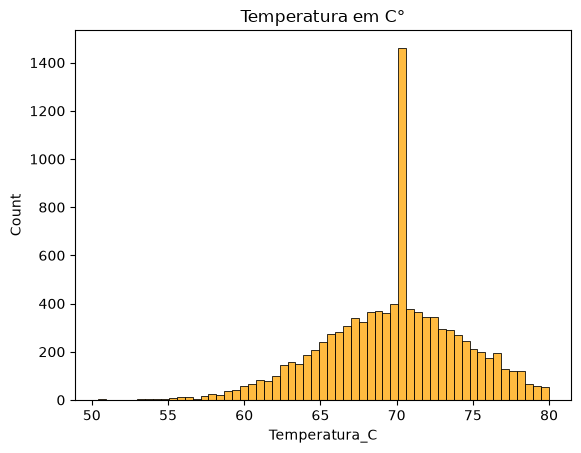

In [33]:
srn.histplot(dataset['Temperatura_C'], color = 'orange').set_title('Temperatura em C°')

Text(0.5, 1.0, 'Vibração em mms')

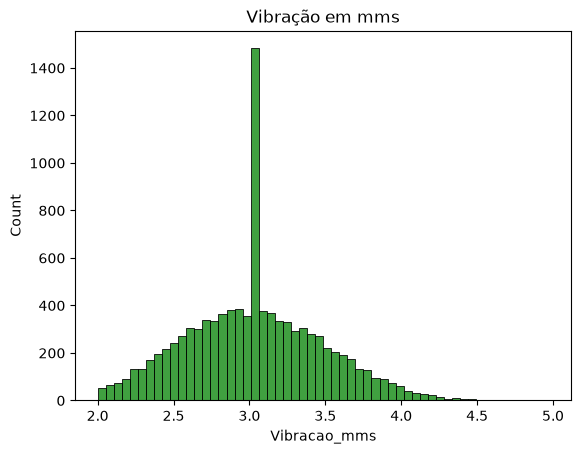

In [34]:
srn.histplot(dataset['Vibracao_mms'], color = 'green').set_title('Vibração em mms')

Text(0.5, 1.0, 'Pressão em bar')

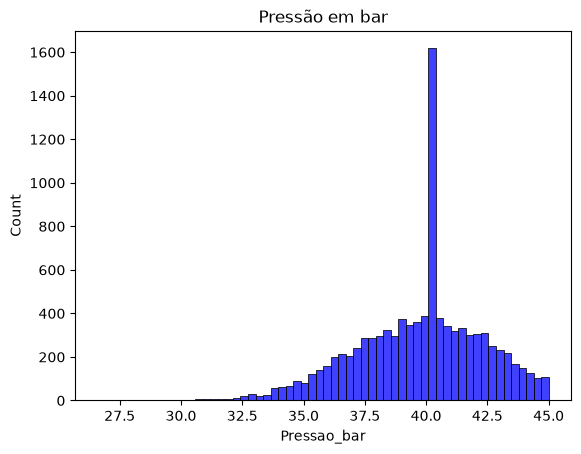

In [35]:
srn.histplot(dataset['Pressao_bar'], color = 'blue').set_title('Pressão em bar')

In [36]:
dataset.to_csv(r"C:\Users\henrique_schorck\Documents\GitHub\Projeto-Integrador\Machine_Learning\Dados_CSV\dados_limpos.csv", index=False, sep=',', encoding='utf-8')
#Criação de CSV automatico com os dados ja limpos, que serão alimentados para a IA depois

               Temperatura_C  Vibracao_mms  Pressao_bar  Falha_motor
Temperatura_C       1.000000      0.006799     0.022121     0.032133
Vibracao_mms        0.006799      1.000000     0.022878    -0.000529
Pressao_bar         0.022121      0.022878     1.000000     0.043507
Falha_motor         0.032133     -0.000529     0.043507     1.000000


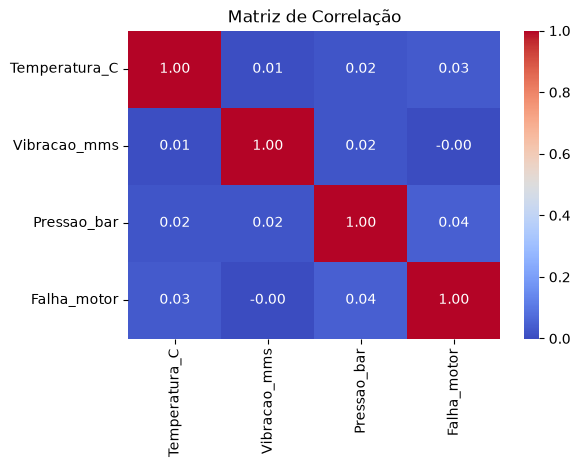

In [37]:
colunas_interesse = ['Temperatura_C', 'Vibracao_mms', 'Pressao_bar', 'Falha_motor']
matriz_corr = dataset[colunas_interesse].corr()

print(matriz_corr)

plt.figure(figsize=(6, 4))
srn.heatmap(matriz_corr, annot=True, cmap='coolwarm', fmt=".2f")
plt.title('Matriz de Correlação')
plt.show()

In [38]:
x = dataset[['Vibracao_mms', 'Pressao_bar', 'Temperatura_C']]
y = dataset['Falha_motor']

x_train, x_test, y_train, y_test = train_test_split(x, y, test_size=0.2, random_state=42)

In [39]:
model_linearRegression = LinearRegression()
model_forestRegression = RandomForestRegressor(random_state=42)

In [40]:
model_linearRegression.fit(x_train, y_train)
model_forestRegression.fit(x_train, y_train)

,"random_state random_state: int, RandomState instance or None, default=NoneControls both the randomness of the bootstrapping of the samples usedwhen building trees (if ``bootstrap=True``) and the sampling of thefeatures to consider when looking for the best split at each node(if ``max_features < n_features``).See :term:`Glossary <random_state>` for details.",42
,"n_estimators n_estimators: int, default=100The number of trees in the forest... versionchanged:: 0.22 The default value of ``n_estimators`` changed from 10 to 100 in 0.22.",100
,"criterion criterion: {""squared_error"", ""absolute_error"", ""poisson""}, default=""squared_error""The function to measure the quality of a split. Supported criteriaare ""squared_error"" for the mean squared error, which is equal tovariance reduction as feature selection criterion and minimizes the L2loss using the mean of each terminal node, ""absolute_error"" for the meanabsolute error, which minimizes the L1 loss using the median of each terminalnode, and ""poisson"" which uses reduction in Poisson deviance to find splits,also using the mean of each terminal node... versionadded:: 0.18 Mean Absolute Error (MAE) criterion... versionadded:: 1.0 Poisson criterion... versionchanged:: 1.9 Criterion `""friedman_mse""` was deprecated.",'squared_error'
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",None
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: {""sqrt"", ""log2"", None}, int or float, default=1.0The number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None or 1.0, then `max_features=n_features`... note:: The default of 1.0 is equivalent to bagged trees and more randomness can be achieved by setting smaller values, e.g. 0.3... versionchanged:: 1.1 The default of `max_features` changed from `""auto""` to 1.0.Note: the search for a split does not stop until at least onevalid partition of the node samples is found, even if it requires toeffectively inspect more than ``max_features`` features.",1.0
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow trees with ``max_leaf_nodes`` in best-first fashion.Best nodes are defined as relative reduction in impurity.If None then unlimited number of leaf nodes.",None
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease o

In [41]:
prediction_linearRegression = model_linearRegression.predict(x_test)
prediction_forestRegression = model_forestRegression.predict(x_test)

print("\n--- Avaliação de Desempenho (R²) ---")
print(f"Regressão Linear: {metrics.r2_score(y_test, prediction_linearRegression):.2%}")
print(f"Random Forest: {metrics.r2_score(y_test, prediction_forestRegression):.2%}")


--- Avaliação de Desempenho (R²) ---
Regressão Linear: 0.22%
Random Forest: 98.61%


In [42]:
new_attempts = pd.DataFrame({
    'Vibracao_mms': [3.0, 5.0, 18.0, 30.2],
    'Pressao_bar': [39.2, 80.8, 26.7, 120.3],
    'Temperatura_C': [120.9, 70.5, 56.1, 200.6]
})

new_scenarios_predictions = model_linearRegression.predict(new_attempts)
new_attempts['Chance de falha do motor'] = new_scenarios_predictions

print("\n--- Previsões para falhas de novos motores")
display(new_attempts)


--- Previsões para falhas de novos motores


,Vibracao_mms,Pressao_bar,Temperatura_C,Chance de falha do motor
0,3.0,39.2,120.9,0.129851
1,5.0,80.8,70.5,0.201371
2,18.0,26.7,56.1,-0.033502
3,30.2,120.3,200.6,0.530516


In [43]:
#Exportação do ficheiro .joblib do modelo treinado (regressão linear)
joblib.dump(model_linearRegression, r'C:\Users\henrique_schorck\Documents\GitHub\Projeto-Integrador\Machine_Learning\Registro\ficheiro.joblib')

['C:\\Users\\henrique_schorck\\Documents\\GitHub\\Projeto-Integrador\\Machine_Learning\\Registro\\ficheiro.joblib']